In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("uber.csv")

print(df.head())
print(df.info())
print(df.describe())


df.isnull().sum()



   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [5]:
df = df.drop(columns=["Unnamed: 0", "key"])

df = df.dropna()

df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

df.head()


# df.drop(columns=["Unnamed: 0", "key"], inplace=True)


,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5


In [6]:
def haversine_distance(lat1, lon1, lat2, lon2):
    r = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    distance = 2 * r * np.arcsin(np.sqrt(a))

    return distance

df["distance_km"] = haversine_distance(df["pickup_latitude"], df["pickup_longitude"], df["dropoff_latitude"], df["dropoff_longitude"])

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

df = df.drop(columns=["pickup_datetime"])

df.head()
    

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance_km,hour,day,month,year,day_of_week
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,1.683323,19,7,5,2015,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,2.457590,20,17,7,2009,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,5.036377,21,24,8,2009,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,1.661683,8,26,6,2009,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,4.475450,17,28,8,2014,3


count    199999.000000
mean         11.359892
std           9.901760
min         -52.000000
25%           6.000000
50%           8.500000
75%          12.500000
max         499.000000
Name: fare_amount, dtype: float64


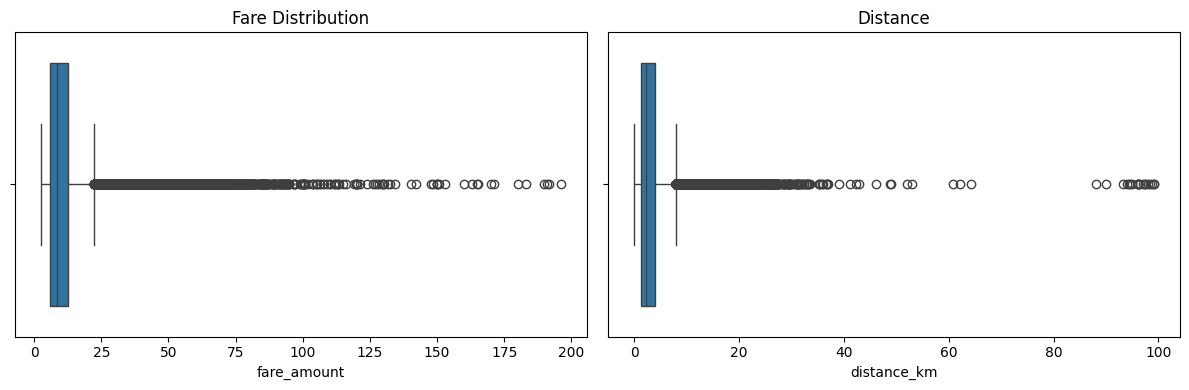

In [7]:
print(df["fare_amount"].describe())

# df = df[(df['fare_amount'] >= 0) & (df['passenger_count'] > 0) & (df['distance_km'] > 0) & (df['pickup_longitude'].between(-180, 180))
# & df['pickup_latitude'].between(-90, 90) &   df['dropoff_latitude'].between(-90, 90) & df['dropoff_longitude'].between(-180, 180) ]

df = df[
    (df['fare_amount'] >= 2.5) & (df['fare_amount'] <= 200) &          # Realistic fares
    (df['passenger_count'] > 0) & (df['passenger_count'] <= 6) &        # Realistic passengers
    (df['distance_km'] > 0) & (df['distance_km'] <= 100) &              # Reasonable distance (< 100 km)
    (df['pickup_latitude'].between(40.0, 42.0)) &                       # NYC Latitude range
    (df['pickup_longitude'].between(-75.0, -72.0)) &                    # NYC Longitude range
    (df['dropoff_latitude'].between(40.0, 42.0)) & 
    (df['dropoff_longitude'].between(-75.0, -72.0))
]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(x = df['fare_amount'])
plt.title('Fare Distribution');

plt.subplot(1, 2, 2)
sns.boxplot(x = df['distance_km'])
plt.title('Distance')

plt.tight_layout()
plt.show()

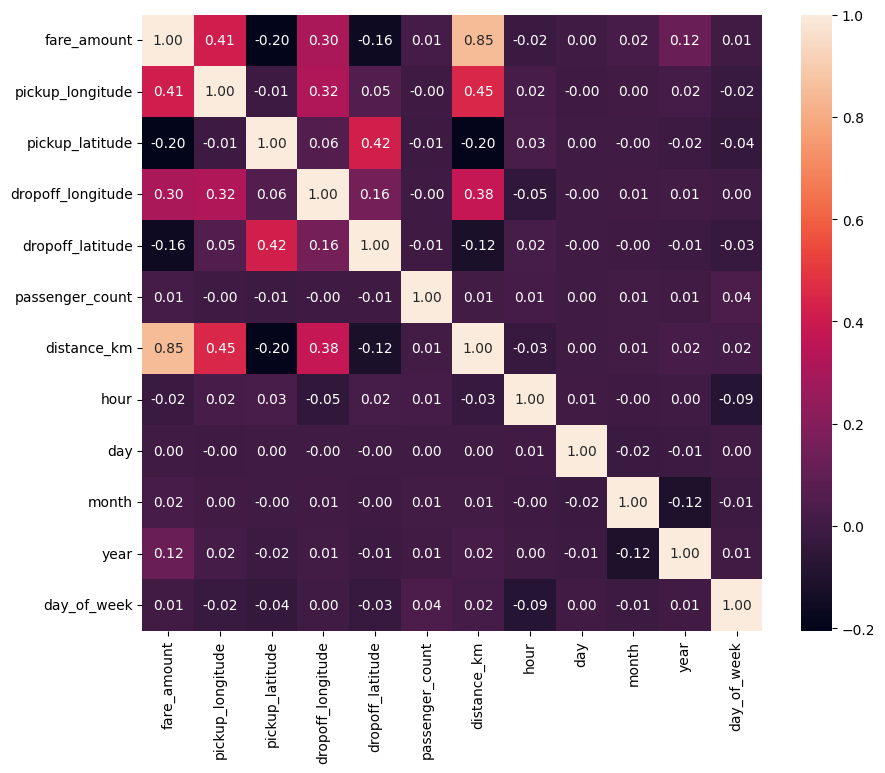

In [8]:
plt.figure(figsize=(10, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()


# sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidth=0.5)
# plt.title("heatmap")
# plt.show()

fare_correlation = correlation_matrix['fare_amount'].sort_values(ascending=False)

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

X = df.drop(columns=['fare_amount'])
y = df['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LinearRegression()
# rf_model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=10, max_depth=15)

lr_model.fit(X_train_scaled, y_train)
rf_model.fit(X_train, y_train)

lr_preds = lr_model.predict(X_test_scaled)
rf_preds = rf_model.predict(X_test)

In [10]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = float(np.sqrt(mse))
    r2 = r2_score(y_true, y_pred)

    return {
        'Model' : model_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    }

lr_results = evaluate_model(y_test, lr_preds, "lr")
rf_results = evaluate_model(y_test, rf_preds, "rf")

print(lr_results)
print(rf_results)

{'Model': 'lr', 'MAE': 2.3356265292263845, 'RMSE': 5.314127062366841, 'R2 Score': 0.6989124781441263}
{'Model': 'rf', 'MAE': 1.8674832279570963, 'RMSE': 3.8832870773554147, 'R2 Score': 0.8392215329097226}
